# TSE BSRNN – test & listen
Run on a GPU runtime. Cells 1–3 set up, 4 loads the checkpoint, 5 lets you listen, 6 computes metrics on the test set.

In [2]:
# 1) Mount Drive + install deps
from google.colab import drive
drive.mount("/content/drive")
!pip -q install speechbrain pystoi pyyaml
!pip -q install pesq 2>&1 | tail -1

Mounted at /content/drive


In [3]:
# 2) Re-download ONLY what the test set needs (test-clean + DEMAND). Colab disk is wiped between runtimes.
import os
DATA = "/content/tse-project/DATA"
os.environ["DATA"] = DATA
os.makedirs(f"{DATA}/dl", exist_ok=True); os.makedirs(f"{DATA}/DEMAND", exist_ok=True); os.makedirs(f"{DATA}/LibriSpeech", exist_ok=True)

if not os.path.isdir(f"{DATA}/LibriSpeech/test-clean"):
    !apt-get -qq install -y aria2 > /dev/null
    !cd $DATA/dl && aria2c -x 16 -s 16 -k 4M -c -q https://www.openslr.org/resources/12/test-clean.tar.gz && tar -xzf test-clean.tar.gz -C $DATA && rm test-clean.tar.gz
print("test-clean speakers:", len(os.listdir(f"{DATA}/LibriSpeech/test-clean")))

test-clean speakers: 40


In [8]:
# 3) DEMAND noise (same source as in training)
from huggingface_hub import snapshot_download
import glob, zipfile
ZIP_DIR, OUT_DIR = f"{DATA}/dl", f"{DATA}/DEMAND"
snapshot_download("Sostika/demand", repo_type="dataset", local_dir=ZIP_DIR, allow_patterns=["*_16k.zip"])
for z in sorted(glob.glob(f"{ZIP_DIR}/*_16k.zip")):
    name = os.path.basename(z).replace("_16k.zip", "")
    target = f"{OUT_DIR}/{name}"
    if sum(f.endswith(".wav") for _, _, fs in os.walk(target) for f in fs) >= 16:
        continue
    with zipfile.ZipFile(z) as zf: zf.extractall(target)
    os.remove(z)
print(sorted(os.listdir(OUT_DIR)))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

['DKITCHEN', 'DLIVING', 'DWASHING', 'NFIELD', 'NPARK', 'NRIVER', 'OHALLWAY', 'OMEETING', 'OOFFICE', 'PRESTO', 'PSTATION', 'SPSQUARE', 'STRAFFIC', 'TBUS', 'TCAR', 'TMETRO']


In [6]:
# 4) Load project lib, config, data, and the trained checkpoint
import sys, gc, numpy as np, pandas as pd, torch
PROJ = "/content/drive/MyDrive/tse-project"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
sys.path.insert(0, PROJ)
import tselib as T
import os
import glob

cfg_big = T.load_cfg(f"{PROJ}/config_big.yaml")   # saved by your training notebook
D = T.proj_dirs(cfg_big)
TAG = "tse_bsrnn_big"

banks    = {r: T.load_bank(f"{D['embeddings']}/{r}") for r in ["test"]}
man_test = pd.read_csv(f"{D['manifests']}/test_mix.csv")
test_ds  = T.FixedDataset(man_test, banks["test"][1], DATA, cfg_big["audio"]["eval_seconds"], cfg_big["mix"]["peak_limit"])
print("test mixtures:", len(test_ds))

# find checkpoint (prefers *best*, otherwise newest)
cands = sorted(glob.glob(f"{D['checkpoints']}/*{TAG}*"), key=os.path.getmtime)
print("checkpoints found:"); [print("  ", os.path.basename(c)) for c in cands]
best = [c for c in cands if "best" in os.path.basename(c).lower()]
CKPT = (best or cands)[-1]          # <- override manually if you want a specific one
print("using:", CKPT)

ck = torch.load(CKPT, map_location="cpu", weights_only=False)
if isinstance(ck, dict):
    state = next((ck[k] for k in ("model", "model_state", "model_state_dict", "state_dict", "net") if k in ck), ck)
    print("checkpoint keys:", list(ck.keys())[:10])
else:
    state = ck
state = {k.replace("module.", "", 1): v for k, v in state.items()}
model = T.TSEBSRNN(cfg_big["model"])
print(model.load_state_dict(state, strict=False))
model = model.to(device).eval()

test mixtures: 1200
checkpoints found:
   tse_bsrnn_big_best.pt
   tse_bsrnn_big_last.pt
using: /content/drive/MyDrive/tse-project/checkpoints/tse_bsrnn_big_best.pt
checkpoint keys: ['model', 'cfg', 'epoch', 'val_si_sdri']
<All keys matched successfully>


In [9]:
# 5) Listen: mixture vs. model output vs. clean target
from IPython.display import Audio, display
import matplotlib.pyplot as plt
SR = 16000

def si_sdr(est, ref, eps=1e-8):
    est, ref = est - est.mean(), ref - ref.mean()
    proj = (est @ ref) / (ref @ ref + eps) * ref
    return 10 * np.log10((proj @ proj) / (((est - proj) @ (est - proj)) + eps) + eps)

@torch.no_grad()
def run(i):
    mix, tgt, emb, *_ = test_ds[i]
    mix, tgt, emb = [torch.as_tensor(x) for x in (mix, tgt, emb)]
    m = mix.reshape(1, -1).to(device); e = emb.reshape(1, -1).to(device) if emb.ndim < 2 else emb.unsqueeze(0).to(device) if emb.ndim == 2 and emb.shape[0] != 1 else emb.to(device)
    with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
        est = model(m, e)
    return mix.reshape(-1).numpy(), tgt.reshape(-1).numpy(), est.float().reshape(-1).cpu().numpy()

os.makedirs(f"{PROJ}/samples", exist_ok=True)
import soundfile as sf
rng = np.random.default_rng(0)
for i in rng.choice(len(test_ds), 20, replace=False):
    mix, tgt, est = run(int(i))
    n = min(len(mix), len(tgt), len(est)); mix, tgt, est = mix[:n], tgt[:n], est[:n]
    s_in, s_out = si_sdr(mix, tgt), si_sdr(est, tgt)
    print(f"=== example {i} | SI-SDR in {s_in:.2f} dB -> out {s_out:.2f} dB (improvement {s_out - s_in:+.2f} dB)")
    for name, x in [("1) Mixture (target + interferer + noise)", mix), ("2) Model output (extracted target)", est), ("3) Clean target (reference)", tgt)]:
        print(name); display(Audio(x, rate=SR))
    for name, x in [("mix", mix), ("est", est), ("tgt", tgt)]:
        sf.write(f"{PROJ}/samples/ex{i}_{name}.wav", x, SR)
    fig, ax = plt.subplots(1, 3, figsize=(15, 2.5), sharey=True)
    for a, (t, x) in zip(ax, [("mixture", mix), ("output", est), ("target", tgt)]):
        a.specgram(x, Fs=SR, NFFT=512, noverlap=384); a.set_title(t)
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [15]:
# 6) Metrics over the whole test set (SI-SDR, SI-SDRi, STOI, PESQ)
from pystoi import stoi
from pesq import pesq
from tqdm.auto import tqdm
rows = []
for i in tqdm(range(len(test_ds))):
    mix, tgt, est = run(i); n = min(len(mix), len(tgt), len(est)); mix, tgt, est = mix[:n], tgt[:n], est[:n]
    try: p = pesq(SR, tgt, est, "wb")
    except Exception: p = np.nan
    rows.append(dict(idx=i, sisdr_in=si_sdr(mix, tgt), sisdr_out=si_sdr(est, tgt),
                     stoi_in=stoi(tgt, mix, SR), stoi_out=stoi(tgt, est, SR), pesq_out=p))
df = pd.DataFrame(rows); df["sisdri"] = df.sisdr_out - df.sisdr_in
display(df.describe().loc[["mean", "std", "min", "max"]].round(2))
df.to_csv(f"{PROJ}/test_metrics.csv", index=False)
print(f"Mean SI-SDRi: {df.sisdri.mean():.2f} dB | STOI {df.stoi_in.mean():.3f} -> {df.stoi_out.mean():.3f}")

  0%|          | 0/1200 [00:00<?, ?it/s]

,idx,sisdr_in,sisdr_out,stoi_in,stoi_out,pesq_out,sisdri
mean,599.50,5.95,13.92,0.78,0.89,2.50,7.97
std,346.55,24.19,12.30,0.14,0.16,0.93,17.28
min,0.00,-11.85,-31.05,0.40,0.08,1.02,-87.45
max,1199.00,113.00,54.79,1.00,1.00,4.64,31.77


Mean SI-SDRi: 7.97 dB | STOI 0.785 -> 0.888


Mixture: 13.4s
Enrollment: 15.6s


INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


hyperparams.yaml:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Fetching from HuggingFace Hub 'speechbrain/spkrec-ecapa-voxceleb' if not cached


embedding_model.ckpt: reconstructing file:   0%|          |  0.00B / 83.3MB            

embedding_model.ckpt: downloading bytes:           |  0.00B            

... (11 outputs left out)

Saved: /content/extracted.wav


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/matplotlib/axes/_axes.py:8233: RuntimeWarning: divide by zero encountered in log10
  Z = 10. * np.log10(spec)


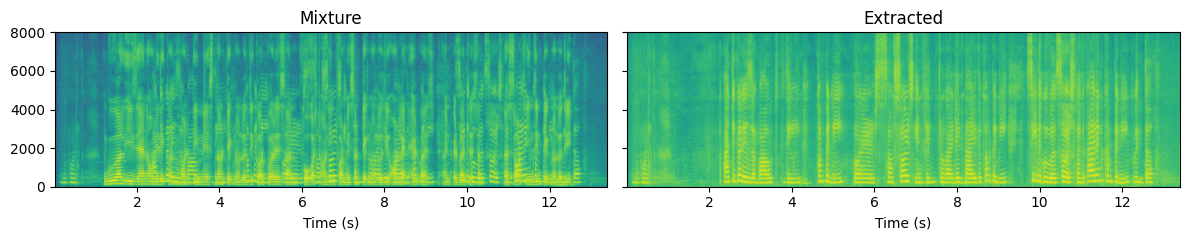

In [11]:
# 7) Separate YOUR OWN files: mixture.wav + enrollment (target.wav)

import os
import torch
import torchaudio
import numpy as np
import soundfile as sf
from IPython.display import Audio, display
import matplotlib.pyplot as plt

SR = 16000

# ---- load already uploaded files ----
MIX_PATH = "/content/mixture.wav"
ENR_PATH = "/content/target.wav"

assert os.path.exists(MIX_PATH), f"Mixture file not found: {MIX_PATH}"
assert os.path.exists(ENR_PATH), f"Enrollment file not found: {ENR_PATH}"

def load_16k_mono(path):
    wav, sr = torchaudio.load(path)
    wav = wav.mean(0, keepdim=True)

    if sr != SR:
        wav = torchaudio.functional.resample(wav, sr, SR)

    return wav  # (1, T)

mix = load_16k_mono(MIX_PATH)
enr = load_16k_mono(ENR_PATH)

print(f"Mixture: {mix.shape[1]/SR:.1f}s")
print(f"Enrollment: {enr.shape[1]/SR:.1f}s")


# ---- enrollment embedding (SpeechBrain ECAPA-TDNN) ----
from speechbrain.inference.speaker import EncoderClassifier

ecapa = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    savedir="/content/ecapa",
    run_opts={"device": str(device)}
)

with torch.no_grad():
    emb = ecapa.encode_batch(enr.to(device)).reshape(1, -1)

# ---- sanity check against training embedding ----
ref = torch.as_tensor(test_ds[0][2])

print("Your embedding:", tuple(emb.shape))
print("Training embedding:", tuple(ref.shape))

print("Training embedding norm:", ref.float().norm().item())
print("Your embedding norm:", emb.norm().item())

# If training embeddings are L2-normalised, uncomment:
# emb = torch.nn.functional.normalize(emb, dim=-1)


# ---- separate ----
with torch.no_grad():
    with torch.autocast(
        "cuda",
        dtype=torch.float16,
        enabled=device.type == "cuda"
    ):
        est = model(mix.to(device), emb)

est = est.float().reshape(-1).cpu().numpy()
mixn = mix.reshape(-1).numpy()

# Normalise extracted audio for listening
est = est / (np.abs(est).max() + 1e-8) * 0.9


# ---- listen ----
print("1) Mixture")
display(Audio(mixn, rate=SR))

print("2) Extracted (model)")
display(Audio(est, rate=SR))

print("3) Enrollment (target speaker)")
display(Audio(enr.reshape(-1).numpy(), rate=SR))


# ---- save extracted audio ----
OUTPUT_PATH = "/content/extracted.wav"

sf.write(OUTPUT_PATH, est, SR)

print("Saved:", OUTPUT_PATH)


# ---- download extracted audio ----
from google.colab import files
files.download(OUTPUT_PATH)


# ---- visualize spectrograms ----
fig, ax = plt.subplots(1, 2, figsize=(12, 2.5), sharey=True)

for a, (t, x) in zip(
    ax,
    [("Mixture", mixn), ("Extracted", est)]
):
    a.specgram(x, Fs=SR, NFFT=512, noverlap=384)
    a.set_title(t)
    a.set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/content/ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/content/ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/content/ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/content/ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/content/ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


Mixture: 15.7s
Enrollment: 15.6s


Your embedding: (1, 192)
Training embedding: (192,)
Training embedding norm: 238.4318084716797
Your embedding norm: 290.7889404296875
1) Mixture


2) Extracted (model)


3) Enrollment (target speaker)


Saved: /content/extracted2.wav


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

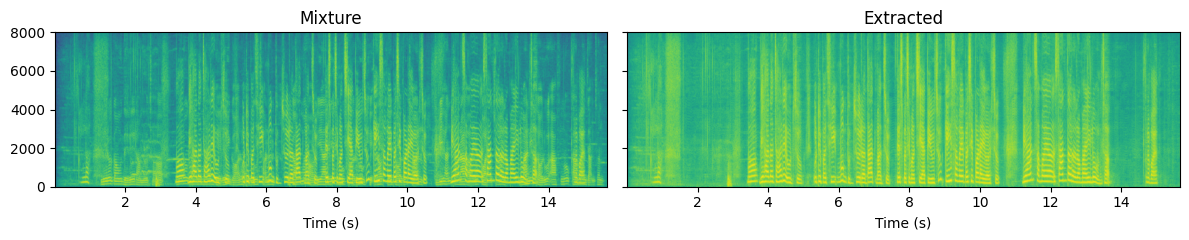

In [13]:
# 7) Separate YOUR OWN files: mixture.wav + enrollment (target.wav)

import os
import torch
import torchaudio
import numpy as np
import soundfile as sf
from IPython.display import Audio, display
import matplotlib.pyplot as plt

SR = 16000

# ---- load already uploaded files ----
MIX_PATH = "/content/mixture2.wav"
ENR_PATH = "/content/target.wav"

assert os.path.exists(MIX_PATH), f"Mixture file not found: {MIX_PATH}"
assert os.path.exists(ENR_PATH), f"Enrollment file not found: {ENR_PATH}"

def load_16k_mono(path):
    wav, sr = torchaudio.load(path)
    wav = wav.mean(0, keepdim=True)

    if sr != SR:
        wav = torchaudio.functional.resample(wav, sr, SR)

    return wav  # (1, T)

mix = load_16k_mono(MIX_PATH)
enr = load_16k_mono(ENR_PATH)

print(f"Mixture: {mix.shape[1]/SR:.1f}s")
print(f"Enrollment: {enr.shape[1]/SR:.1f}s")


# ---- enrollment embedding (SpeechBrain ECAPA-TDNN) ----
from speechbrain.inference.speaker import EncoderClassifier

ecapa = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    savedir="/content/ecapa",
    run_opts={"device": str(device)}
)

with torch.no_grad():
    emb = ecapa.encode_batch(enr.to(device)).reshape(1, -1)

# ---- sanity check against training embedding ----
ref = torch.as_tensor(test_ds[0][2])

print("Your embedding:", tuple(emb.shape))
print("Training embedding:", tuple(ref.shape))

print("Training embedding norm:", ref.float().norm().item())
print("Your embedding norm:", emb.norm().item())

# If training embeddings are L2-normalised, uncomment:
# emb = torch.nn.functional.normalize(emb, dim=-1)


# ---- separate ----
with torch.no_grad():
    with torch.autocast(
        "cuda",
        dtype=torch.float16,
        enabled=device.type == "cuda"
    ):
        est = model(mix.to(device), emb)

est = est.float().reshape(-1).cpu().numpy()
mixn = mix.reshape(-1).numpy()

# Normalise extracted audio for listening
est = est / (np.abs(est).max() + 1e-8) * 0.9


# ---- listen ----
print("1) Mixture")
display(Audio(mixn, rate=SR))

print("2) Extracted (model)")
display(Audio(est, rate=SR))

print("3) Enrollment (target speaker)")
display(Audio(enr.reshape(-1).numpy(), rate=SR))


# ---- save extracted audio ----
OUTPUT_PATH = "/content/extracted2.wav"

sf.write(OUTPUT_PATH, est, SR)

print("Saved:", OUTPUT_PATH)


# ---- download extracted audio ----
from google.colab import files
files.download(OUTPUT_PATH)


# ---- visualize spectrograms ----
fig, ax = plt.subplots(1, 2, figsize=(12, 2.5), sharey=True)

for a, (t, x) in zip(
    ax,
    [("Mixture", mixn), ("Extracted", est)]
):
    a.specgram(x, Fs=SR, NFFT=512, noverlap=384)
    a.set_title(t)
    a.set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

INFO:speechbrain.utils.fetching:Fetch hyperparams.yaml: Using symlink found at '/content/ecapa/hyperparams.yaml'
INFO:speechbrain.utils.fetching:Fetch embedding_model.ckpt: Using symlink found at '/content/ecapa/embedding_model.ckpt'
INFO:speechbrain.utils.fetching:Fetch mean_var_norm_emb.ckpt: Using symlink found at '/content/ecapa/mean_var_norm_emb.ckpt'
INFO:speechbrain.utils.fetching:Fetch classifier.ckpt: Using symlink found at '/content/ecapa/classifier.ckpt'
INFO:speechbrain.utils.fetching:Fetch label_encoder.txt: Using symlink found at '/content/ecapa/label_encoder.ckpt'
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: embedding_model, mean_var_norm_emb, classifier, label_encoder


Mixture: 15.7s
Enrollment: 14.9s


Your embedding: (1, 192)
Training embedding: (192,)
Training embedding norm: 238.4318084716797
Your embedding norm: 263.6620178222656
1) Mixture


2) Extracted (model)


3) Enrollment (target speaker)


Saved: /content/extracted2.wav


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

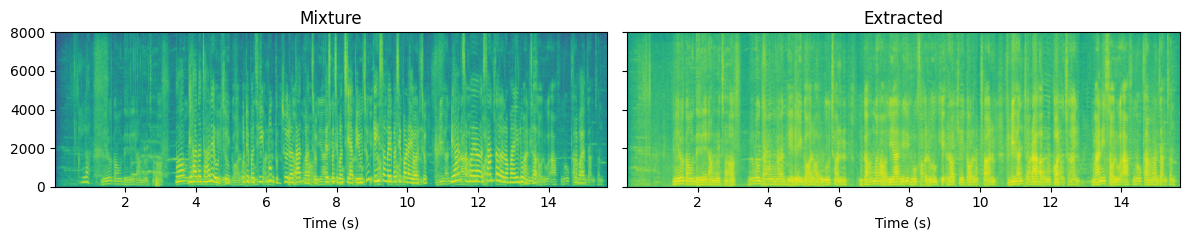

In [14]:
# 7) Separate YOUR OWN files: mixture.wav + enrollment (target.wav)

import os
import torch
import torchaudio
import numpy as np
import soundfile as sf
from IPython.display import Audio, display
import matplotlib.pyplot as plt

SR = 16000

# ---- load already uploaded files ----
MIX_PATH = "/content/mixture2.wav"
ENR_PATH = "/content/enrollment.wav"

assert os.path.exists(MIX_PATH), f"Mixture file not found: {MIX_PATH}"
assert os.path.exists(ENR_PATH), f"Enrollment file not found: {ENR_PATH}"

def load_16k_mono(path):
    wav, sr = torchaudio.load(path)
    wav = wav.mean(0, keepdim=True)

    if sr != SR:
        wav = torchaudio.functional.resample(wav, sr, SR)

    return wav  # (1, T)

mix = load_16k_mono(MIX_PATH)
enr = load_16k_mono(ENR_PATH)

print(f"Mixture: {mix.shape[1]/SR:.1f}s")
print(f"Enrollment: {enr.shape[1]/SR:.1f}s")


# ---- enrollment embedding (SpeechBrain ECAPA-TDNN) ----
from speechbrain.inference.speaker import EncoderClassifier

ecapa = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    savedir="/content/ecapa",
    run_opts={"device": str(device)}
)

with torch.no_grad():
    emb = ecapa.encode_batch(enr.to(device)).reshape(1, -1)

# ---- sanity check against training embedding ----
ref = torch.as_tensor(test_ds[0][2])

print("Your embedding:", tuple(emb.shape))
print("Training embedding:", tuple(ref.shape))

print("Training embedding norm:", ref.float().norm().item())
print("Your embedding norm:", emb.norm().item())

# If training embeddings are L2-normalised, uncomment:
# emb = torch.nn.functional.normalize(emb, dim=-1)


# ---- separate ----
with torch.no_grad():
    with torch.autocast(
        "cuda",
        dtype=torch.float16,
        enabled=device.type == "cuda"
    ):
        est = model(mix.to(device), emb)

est = est.float().reshape(-1).cpu().numpy()
mixn = mix.reshape(-1).numpy()

# Normalise extracted audio for listening
est = est / (np.abs(est).max() + 1e-8) * 0.9


# ---- listen ----
print("1) Mixture")
display(Audio(mixn, rate=SR))

print("2) Extracted (model)")
display(Audio(est, rate=SR))

print("3) Enrollment (target speaker)")
display(Audio(enr.reshape(-1).numpy(), rate=SR))


# ---- save extracted audio ----
OUTPUT_PATH = "/content/extracted2.wav"

sf.write(OUTPUT_PATH, est, SR)

print("Saved:", OUTPUT_PATH)


# ---- download extracted audio ----
from google.colab import files
files.download(OUTPUT_PATH)


# ---- visualize spectrograms ----
fig, ax = plt.subplots(1, 2, figsize=(12, 2.5), sharey=True)

for a, (t, x) in zip(
    ax,
    [("Mixture", mixn), ("Extracted", est)]
):
    a.specgram(x, Fs=SR, NFFT=512, noverlap=384)
    a.set_title(t)
    a.set_xlabel("Time (s)")

plt.tight_layout()
plt.show()